# ДЗ №2. Влияние рыночного фактора, фактора размера и фактора стоимости на доходность российских акций

**Курс:** Теория финансов, Лекция 3 — «Базовое уравнение ценообразования. Классические модели ценообразования активов».

**Цель:** оценить, насколько доходности 35 российских акций объясняются рыночным фактором (CAPM)
и тремя факторами Фамы–Френча (рынок, размер SMB, стоимость HML), и сравнить премии за риск двух моделей.

**Задачи:**
1. Собрать месячные доходности акций с учётом дивидендов, рыночный индекс и безрисковую ставку.
2. Оценить для каждой акции временные регрессии CAPM и трёхфакторной модели.
3. Сравнить модели: объяснительная сила (R²), альфы, совместный тест GRS, процедура Фамы–Макбета.
4. Посчитать и сравнить премии за риск и требуемую доходность по двум моделям.
5. Проверить устойчивость выводов (доходности без дивидендов, другая безрисковая ставка, другой рыночный фактор)
   и посмотреть, что дают дополнительные факторы (моментум, ликвидность).

**Данные** (скрипты загрузки — в папке `scripts/`):

| Что | Источник | Период |
|---|---|---|
| Месячные цены закрытия 35 акций, индексы IMOEX и MCFTR | Мосбиржа, ISS API, режим TQBR | 01.2015–09.2026 |
| Дивиденды на акцию, даты закрытия реестра | dohod.ru (сверка со smart-lab.ru) | 2015–2026 |
| RUONIA (дневная), кривая бескупонной доходности ОФЗ | Банк России | 2015–2026 |
| Факторы SMB, HML, MOM, LIQ и др. | CAPM-RU, ИПЭИ РАНХиГС (А.Е. Абрамов), aea.ru | по 12.2024 |

Факторы РАНХиГС заканчиваются в 12.2024, поэтому **основной период оценки — 02.2015–12.2024 (119 месяцев)**.

In [1]:
# Библиотеки: pandas/numpy — работа с таблицами, statsmodels — регрессии МНК,
# scipy — распределения для тестов, matplotlib — графики
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

START, END = "2015-02", "2024-12"   # основной период: по последний месяц факторов РАНХиГС
MIN_OBS = 36                        # минимум 3 года наблюдений для регрессии по акции
NW_LAGS = 3                         # лаги Ньюи–Уэста для стандартных ошибок

## 1. Выборка: какие акции и почему

В выборку вошли 15 бумаг из ДЗ1 и 20 крупнейших по капитализации и ликвидности акций Мосбиржи.
Выборка покрывает основные отрасли российского рынка, поэтому акции различаются по размеру
(от «голубых фишек» SBER, LKOH, GAZP до компаний второго эшелона RENI, MSNG, UPRO, CBOM)
и по оценке (от «акций стоимости» с низким P/B — банки, энергетика, нефть — до «акций роста» — IT и e-commerce).
Именно такой разброс нужен, чтобы факторы размера и стоимости могли проявиться.

Что общего: все бумаги торгуются на одной площадке (Мосбиржа, режим TQBR), в рублях, входят или входили
в индекс Мосбиржи, по всем есть данные о дивидендах. Различия — отрасль, размер, дивидендная политика,
доля государства.

In [2]:
# Отрасль и группа каждой бумаги (ДЗ1 — из первого домашнего задания)
SECTORS = {
    "ROSN": "Нефть и газ", "BANEP": "Нефть и газ", "TRNFP": "Нефть и газ", "LKOH": "Нефть и газ",
    "GAZP": "Нефть и газ", "TATN": "Нефть и газ", "NVTK": "Нефть и газ", "SNGSP": "Нефть и газ",
    "BSPB": "Финансы", "CBOM": "Финансы", "RENI": "Финансы", "SBER": "Финансы", "T": "Финансы",
    "VTBR": "Финансы", "MOEX": "Финансы",
    "MAGN": "Металлы и добыча", "ALRS": "Металлы и добыча", "MTLR": "Металлы и добыча",
    "SELG": "Металлы и добыча", "GMKN": "Металлы и добыча", "PLZL": "Металлы и добыча",
    "CHMF": "Металлы и добыча", "NLMK": "Металлы и добыча", "RUAL": "Металлы и добыча",
    "HYDR": "Электроэнергетика", "FEES": "Электроэнергетика", "UPRO": "Электроэнергетика",
    "MSNG": "Электроэнергетика", "IRAO": "Электроэнергетика",
    "RTKM": "Телеком и IT", "MTSS": "Телеком и IT", "YDEX": "Телеком и IT", "HEAD": "Телеком и IT",
    "OZON": "Потребительский сектор", "X5": "Потребительский сектор",
}
HW1 = ["ROSN", "BANEP", "TRNFP", "BSPB", "CBOM", "RENI", "MAGN", "ALRS", "MTLR",
       "SELG", "HYDR", "FEES", "UPRO", "MSNG", "RTKM"]

## 2. Данные

### 2.1. Доходности акций

Цены Мосбиржи уже скорректированы на сплиты и консолидации (VTBR, GMKN, TRNFP, PLZL, T),
но **не на дивиденды**. Для российских акций дивиденды — существенная часть дохода (у MTSS и SNGSP ~11–12% годовых),
поэтому основная модель строится на **полной доходности**:

$$R_{i,t} = \frac{P_{i,t} + D_{i,t}}{P_{i,t-1}} - 1,$$

где $D_{i,t}$ — дивиденды с экс-дивидендной датой в месяце $t$ (при расчётах T+2 — день до закрытия реестра,
с 31.07.2023 при T+1 — сама дата закрытия реестра). Это согласуется с Фамой–Френчем и с факторами РАНХиГС «с дивидендами».

Склейка переименованных бумаг: YNDX→YDEX, FIVE→X5, HHRU→HEAD (T уже содержит историю TCSG).
Восемь месяцев без торгов FIVE/X5 (05–12.2024) исключены — доходность через разрыв не считается.

In [3]:
ret_total = pd.read_csv(DATA / "processed/ret_total.csv", index_col="month")   # с дивидендами
ret_price = pd.read_csv(DATA / "processed/ret_price.csv", index_col="month")   # только цены
mkt = pd.read_csv(DATA / "processed/market_rf.csv", index_col="month")
for df in (ret_total, ret_price, mkt):
    df.index = pd.PeriodIndex(df.index, freq="M")

TICKERS = list(ret_total.columns)
print("Акций:", len(TICKERS))
mkt.tail()

Акций: 35


,imoex_ret,mcftr_ret,rf_ruonia,rf_ofz3m,ofz1y_annual
month,,,,,
2026-05,-0.035,-0.024,0.012,0.010,0.130
2026-06,-0.085,-0.083,0.012,0.011,0.134
2026-07,-0.052,-0.012,0.012,0.011,0.136
2026-08,-0.021,-0.020,0.012,0.011,0.136
2026-09,0.040,0.044,0.012,0.010,0.137


### 2.2. Безрисковая ставка

Ключевая ставка в 2015–2026 гг. менялась от 4,25% до 21%, поэтому одна средняя ставка на весь период
исказила бы избыточные доходности. Берём **свою ставку на каждый месяц**:

* **основной вариант — RUONIA за месяц**: дневные ставки овернайт капитализируются по календарным дням
  (ставка пятницы действует и в выходные, ACT/365). Это доход безрискового рублёвого размещения «овернайт» за месяц —
  аналог 1-месячных T-bills у Фамы и Френча;
* **проверка устойчивости — 3-месячные ОФЗ** с G-кривой ЦБ на конец *предыдущего* месяца
  (ставка, известная инвестору заранее), месячная ставка $(1+y)^{1/12}-1$.

Почему не RGBI, как у РАНХиГС: в их файлах «безрисковая ставка» — это месячное изменение ценового индекса ОФЗ RGBI
(без купонов). Покажем, что это рисковый актив, а не безрисковая ставка.

In [4]:
ranepa = pd.read_csv(DATA / "raw/ranepa/Factor_premiums_2025-02-05.csv", sep=";", decimal=",")
ranepa.index = pd.PeriodIndex(pd.to_datetime(ranepa["Date"]), freq="M")
long_p = pd.read_csv(DATA / "raw/ranepa/Long_factor_portfolios_2025-02-05.csv", sep=";", decimal=",")
long_p.index = pd.PeriodIndex(pd.to_datetime(long_p["Date"]), freq="M")

# факторы РАНХиГС даны в процентах за месяц -> переводим в доли
fcols = ["RM", "SMB", "HML", "MOM", "LIQ", "RM_TR", "SMB_TR", "HML_TR", "MOM_TR", "LIQ_TR"]
ranepa = ranepa[fcols] / 100
rgbi = long_p["RF_RGBI_Index"] / 100

rf_cmp = pd.DataFrame({"RUONIA": mkt["rf_ruonia"], "ОФЗ 3М": mkt["rf_ofz3m"],
                       "RGBI (РАНХиГС)": rgbi}).loc[START:END] * 100
summary_rf = rf_cmp.describe().T[["mean", "std", "min", "max"]]
summary_rf["месяцев < 0"] = (rf_cmp < 0).sum()
print("Безрисковые ставки, % в месяц, 02.2015–12.2024")
summary_rf

Безрисковые ставки, % в месяц, 02.2015–12.2024


,mean,std,min,max,месяцев < 0
RUONIA,0.787,0.333,0.307,1.804,0
ОФЗ 3М,0.699,0.274,0.302,1.755,0
RGBI (РАНХиГС),0.053,2.790,-15.924,8.093,56


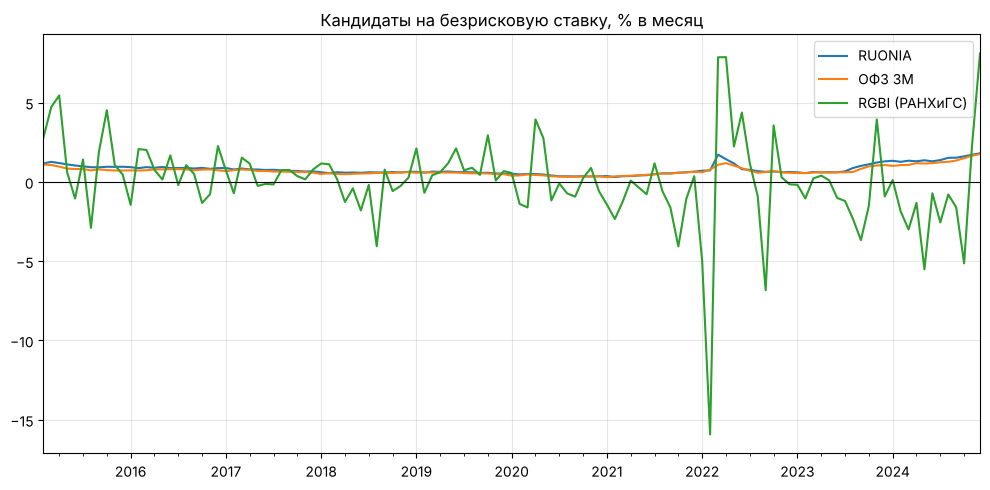

In [5]:
ax = rf_cmp.plot(title="Кандидаты на безрисковую ставку, % в месяц")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "01_rf_compare.png", dpi=150); plt.show()

RGBI падал в 56 месяцах из 119, в феврале 2022 г. — на 16%, а в среднем растёт всего на 0,05% в месяц (купоны в индекс не входят).
RUONIA всегда положительна и почти совпадает с ключевой ставкой. Поэтому рыночный фактор строим сами:

$$MKT_t = R^{MCFTR}_t - r^{RUONIA}_t,$$

где MCFTR — индекс Мосбиржи полной доходности (с реинвестированием дивидендов, согласован с полными доходностями акций).
SMB и HML берём у РАНХиГС как есть: это портфели «длинная минус короткая позиция», безрисковая ставка в разнице сокращается.

In [6]:
# Факторы основной модели (все — в долях за месяц)
F = pd.DataFrame({
    "MKT": mkt["mcftr_ret"] - mkt["rf_ruonia"],
    "SMB": ranepa["SMB_TR"],
    "HML": ranepa["HML_TR"],
}).loc[START:END]

# Избыточные доходности акций над RUONIA
EXR = ret_total.sub(mkt["rf_ruonia"], axis=0).loc[START:END]

print("Периоды:", F.index.min(), "–", F.index.max(), "| месяцев:", len(F))
print("Наблюдений по акциям (мин/медиана/макс):",
      EXR.count().min(), int(EXR.count().median()), EXR.count().max())

Периоды: 2015-02 – 2024-12 | месяцев: 119
Наблюдений по акциям (мин/медиана/макс): 38 119 119


### 2.3. Описательная статистика акций

In [7]:
def ann_stats(r: pd.DataFrame, rf: pd.Series) -> pd.DataFrame:
    """Годовые характеристики по месячным доходностям: среднее ×12, волатильность ×√12, Шарп."""
    ex = r.sub(rf, axis=0)
    out = pd.DataFrame({
        "Отрасль": pd.Series(SECTORS),
        "ДЗ1": pd.Series({t: "да" if t in HW1 else "" for t in r.columns}),
        "Месяцев": r.count(),
        "Доходность, % год.": r.mean() * 1200,
        "Волатильность, % год.": r.std() * np.sqrt(12) * 100,
        "Шарп": ex.mean() / ex.std() * np.sqrt(12),
        "Дивиденды, % год.": (ret_total - ret_price).loc[r.index].mean()[r.columns] * 1200,
    })
    return out.loc[r.columns]

desc = ann_stats(ret_total.loc[START:END], mkt["rf_ruonia"].loc[START:END])
desc.sort_values("Шарп", ascending=False)

,Отрасль,ДЗ1,Месяцев,"Доходность, % год.","Волатильность, % год.",Шарп,"Дивиденды, % год."
BSPB,Финансы,да,119,41.078,36.711,0.862,7.785
PLZL,Металлы и добыча,,119,37.762,40.817,0.695,3.534
SELG,Металлы и добыча,да,119,38.058,45.965,0.620,4.579
IRAO,Электроэнергетика,,119,25.235,29.650,0.534,4.264
SBER,Финансы,,119,27.337,34.362,0.520,5.367
HEAD,Телеком и IT,,51,48.650,74.395,0.513,5.878
LKOH,Нефть и газ,,119,22.676,26.994,0.489,9.214
TATN,Нефть и газ,,119,23.414,30.299,0.463,9.326
MSNG,Электроэнергетика,да,119,24.749,33.961,0.451,5.878
MAGN,Металлы и добыча,да,119,24.224,34.392,0.428,7.172


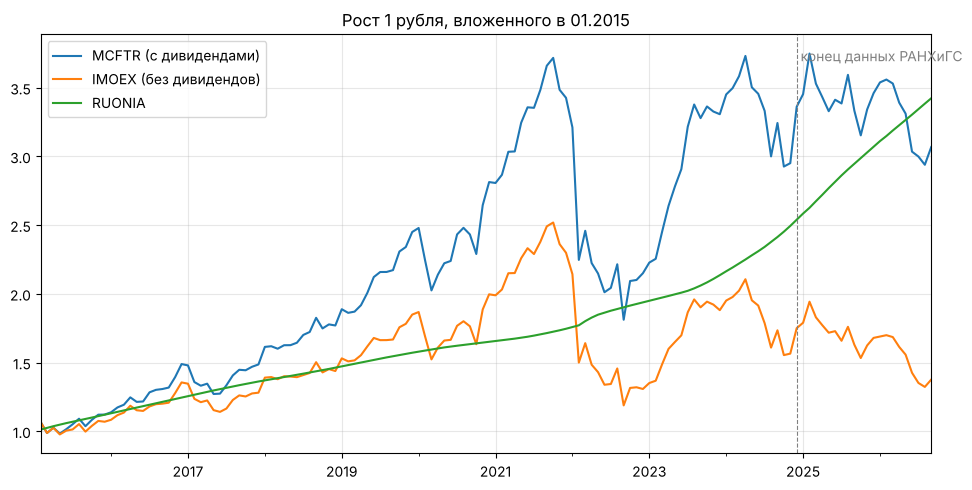

In [8]:
# Накопленный рост 1 рубля: рынок с дивидендами, без дивидендов и безрисковое размещение
grow = (1 + mkt[["mcftr_ret", "imoex_ret", "rf_ruonia"]].loc[START:"2026-09"]).cumprod()
grow.columns = ["MCFTR (с дивидендами)", "IMOEX (без дивидендов)", "RUONIA"]
ax = grow.plot(title="Рост 1 рубля, вложенного в 01.2015")
ax.axvline(pd.Period(END, "M"), color="grey", ls="--", lw=0.8)
ax.text(pd.Period(END, "M"), ax.get_ylim()[1] * 0.95, " конец данных РАНХиГС", color="grey")
ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "02_market_growth.png", dpi=150); plt.show()

### 2.4. Факторы

In [9]:
fac_stats = pd.DataFrame({
    "Среднее, % мес.": F.mean() * 100,
    "Среднее, % год.": F.mean() * 1200,
    "Ст. откл., % мес.": F.std() * 100,
    "t-стат. среднего": F.mean() / F.std() * np.sqrt(F.count()),
})
print("Факторы 02.2015–12.2024")
display(fac_stats)
print("Корреляции факторов")
F.corr()

Факторы 02.2015–12.2024


,"Среднее, % мес.","Среднее, % год.","Ст. откл., % мес.",t-стат. среднего
MKT,0.426,5.118,6.039,0.770
SMB,1.492,17.907,7.354,2.214
HML,-0.280,-3.365,4.422,-0.692


Корреляции факторов


,MKT,SMB,HML
MKT,1.000,-0.080,0.244
SMB,-0.080,1.000,-0.088
HML,0.244,-0.088,1.000


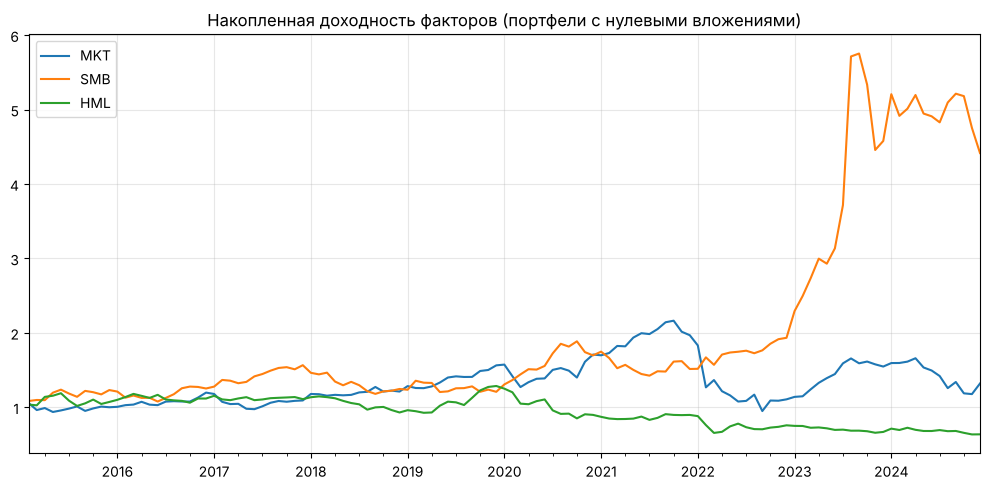

In [10]:
ax = (1 + F).cumprod().plot(title="Накопленная доходность факторов (портфели с нулевыми вложениями)")
ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "03_factors_cum.png", dpi=150); plt.show()

**Наблюдения.** Премия за рыночный риск за 2015–2024 гг. — около 5% годовых, но статистически незначима (t ≈ 0,8):
высокие ставки ЦБ и обвал 2022 г. «съели» большую часть превышения акций над депозитом
(а в 2025–2026 гг. MCFTR и вовсе отстал от RUONIA). SMB в среднем положителен и значим (~18% годовых)
во многом за счёт взрывного роста малых компаний в 2023 г. (SMB за год +137%). HML отрицателен и незначим:
«акции стоимости» в России за десятилетие не обогнали «акции роста».
Корреляции факторов низкие — мультиколлинеарность в регрессиях не грозит.

## 3. Методология

**Шаг 1. Временные регрессии** (для каждой акции $i$ отдельно, МНК по месяцам):

* CAPM: $\;R_{i,t} - r_{f,t} = \alpha_i + \beta_i\,MKT_t + \varepsilon_{i,t}$
* Фама–Френч: $\;R_{i,t} - r_{f,t} = \alpha_i + b_i\,MKT_t + s_i\,SMB_t + h_i\,HML_t + \varepsilon_{i,t}$

Беты — «количество риска» акции; альфа — средняя доходность, которую факторы не объясняют
(если модель верна, $\alpha_i = 0$). Стандартные ошибки — Ньюи–Уэста (HAC, 3 лага): устойчивы
к гетероскедастичности и автокорреляции остатков, что важно для кризисных месяцев (2020, 2022).

**Шаг 2. Сравнение моделей:** R² и скорректированный R², число значимых альф, средняя |α|,
совместный тест GRS (Gibbons, Ross, Shanken, 1989): $H_0: \alpha_1 = \dots = \alpha_N = 0$.

**Шаг 3. Цена риска (Фама–Макбет, 1973):** каждый месяц регрессируем доходности акций на их беты,
усредняем коэффициенты по времени — получаем рыночную оценку премий $\lambda_k$.

**Шаг 4. Премии за риск и требуемая доходность:**
$\;E[R_i] - r_f = \sum_k \beta_{i,k}\,\lambda_k$, где $\lambda_k$ — средняя доходность фактора за период;
требуемая доходность = текущая безрисковая ставка (1-летняя ОФЗ на дату анализа) + премия.

In [11]:
def ts_regress(y: pd.Series, X: pd.DataFrame) -> dict:
    """Временная регрессия y на факторы X с константой; ошибки Ньюи–Уэста."""
    d = pd.concat([y, X], axis=1).dropna()
    if len(d) < MIN_OBS:
        return None
    res = sm.OLS(d.iloc[:, 0], sm.add_constant(d.iloc[:, 1:])).fit(
        cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    out = {"n": int(res.nobs), "R2": res.rsquared, "R2_adj": res.rsquared_adj,
           "resid_vol": res.resid.std() * np.sqrt(12)}
    for k in res.params.index:
        name = "alpha" if k == "const" else k
        out[name] = res.params[k]
        out[f"t_{name}"] = res.tvalues[k]
    return out


def run_model(EXR: pd.DataFrame, X: pd.DataFrame) -> pd.DataFrame:
    """Оценивает модель для всех акций; альфа переводится в % годовых."""
    rows = {t: ts_regress(EXR[t], X) for t in EXR.columns}
    tab = pd.DataFrame({t: r for t, r in rows.items() if r is not None}).T
    tab["alpha_%год"] = tab["alpha"] * 1200
    return tab

## 4. Результаты CAPM

In [12]:
capm = run_model(EXR, F[["MKT"]])
capm_view = capm[["n", "alpha_%год", "t_alpha", "MKT", "t_MKT", "R2"]].rename(
    columns={"MKT": "beta", "t_MKT": "t_beta"})
capm_view.sort_values("beta", ascending=False)

,n,alpha_%год,t_alpha,beta,t_beta,R2
HEAD,51.000,36.181,2.131,1.661,6.638,0.385
OZON,49.000,12.001,0.534,1.525,10.063,0.421
T,62.000,20.419,1.205,1.486,9.467,0.546
MTLR,119.000,8.873,0.462,1.450,5.957,0.243
ROSN,119.000,6.017,0.989,1.369,13.366,0.623
SBER,119.000,11.005,1.637,1.347,10.645,0.671
RENI,38.000,17.894,1.179,1.281,8.618,0.621
FEES,119.000,1.112,0.101,1.182,10.838,0.423
YDEX,119.000,6.116,0.562,1.144,6.423,0.369
NVTK,119.000,1.528,0.243,1.131,14.096,0.567


**Интерпретация CAPM.**
* Все беты положительны и значимы, от 0,55 (CBOM) до 1,66 (HEAD). Выше рынка (β > 1,3) — компании роста и крупнейшие
  банки/нефтяники: HEAD, OZON, T, MTLR, ROSN, SBER. Ниже рынка (β < 0,7) — «защитные» бумаги с регулируемым или
  стабильным бизнесом: электроэнергетика (HYDR, IRAO), телеком (RTKM), привилегированные акции с дивидендной формулой
  (SNGSP, TRNFP), золотодобытчик PLZL (золото — защитный актив в кризис).
* Средний R² ≈ 0,38: рынок объясняет около трети колебаний доходности отдельной акции, остальное — специфический риск.
* Альфы в большинстве незначимы — для большинства акций CAPM не отвергается. Исключения: BSPB (+27% год., t = 2,6),
  HEAD (+36%, t = 2,1) и VTBR (−21%, t = −3,1).

## 5. Результаты трёхфакторной модели Фамы–Френча

In [13]:
ff3 = run_model(EXR, F[["MKT", "SMB", "HML"]])
ff3_view = ff3[["n", "alpha_%год", "t_alpha", "MKT", "t_MKT", "SMB", "t_SMB",
                "HML", "t_HML", "R2", "R2_adj"]].rename(columns={"MKT": "b", "SMB": "s", "HML": "h"})
ff3_view.sort_values("s", ascending=False)

,n,alpha_%год,t_alpha,b,t_MKT,s,t_SMB,h,t_HML,R2,R2_adj
BSPB,119.000,17.984,1.931,0.970,6.698,0.567,7.810,0.434,2.596,0.495,0.482
SELG,119.000,11.537,0.938,1.125,5.702,0.562,3.297,-0.373,-1.228,0.322,0.304
HEAD,51.000,9.684,0.581,1.928,6.673,0.505,4.162,-1.756,-3.632,0.553,0.525
HYDR,119.000,-8.860,-1.221,0.649,5.746,0.278,4.418,0.198,1.401,0.340,0.322
VTBR,119.000,-24.038,-4.004,1.033,8.443,0.274,4.097,0.528,4.398,0.557,0.545
MOEX,119.000,2.328,0.378,0.878,9.082,0.254,2.984,0.115,1.034,0.480,0.466
UPRO,101.000,-13.426,-2.667,0.828,6.742,0.249,4.273,0.138,1.086,0.479,0.463
MTLR,119.000,5.597,0.301,1.421,6.355,0.248,0.866,0.300,1.274,0.257,0.238
PLZL,119.000,18.862,1.417,0.759,3.822,0.221,1.135,-0.481,-1.286,0.165,0.143
X5,74.000,-6.598,-0.515,1.081,5.374,0.198,2.160,-0.305,-1.284,0.357,0.329


In [14]:
# Сколько акций значимо нагружены на каждый фактор (|t| > 1,96)
load_cnt = pd.DataFrame({
    "значимо > 0": [(ff3[f"t_{f}"] > 1.96).sum() for f in ["MKT", "SMB", "HML"]],
    "значимо < 0": [(ff3[f"t_{f}"] < -1.96).sum() for f in ["MKT", "SMB", "HML"]],
}, index=["MKT", "SMB", "HML"])
load_cnt

,значимо > 0,значимо < 0
MKT,35,0
SMB,10,3
HML,7,5


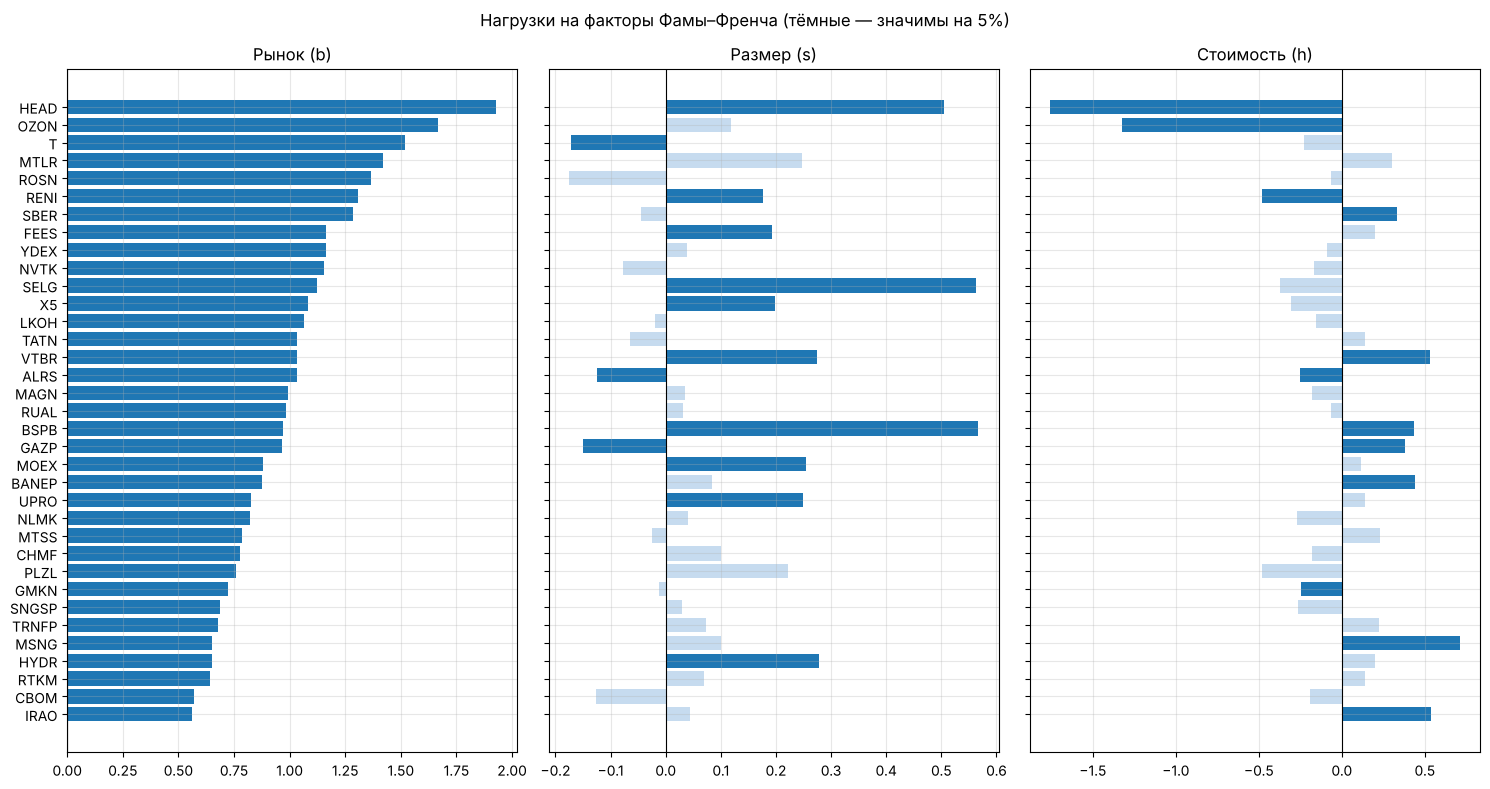

In [15]:
# Беты по трём факторам: кто ведёт себя как малая компания (s>0), кто как акция стоимости (h>0)
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
order = ff3_view.sort_values("b").index
for ax, (col, tcol, title) in zip(axes, [("b", "t_MKT", "Рынок (b)"), ("s", "t_SMB", "Размер (s)"),
                                         ("h", "t_HML", "Стоимость (h)")]):
    vals = ff3_view.loc[order, col]
    sig = ff3_view.loc[order, tcol].abs() > 1.96
    ax.barh(order, vals, color=np.where(sig, "#1f77b4", "#c6dbef"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(title)
fig.suptitle("Нагрузки на факторы Фамы–Френча (тёмные — значимы на 5%)")
plt.tight_layout(); plt.savefig(FIG / "04_ff3_betas.png", dpi=150); plt.show()

**Интерпретация трёхфакторной модели.** Нагрузки экономически осмысленны:
* **Размер (s > 0, ведут себя как малые компании):** BSPB, SELG, HEAD, HYDR, VTBR, MOEX, UPRO, X5, FEES, RENI.
  **s < 0 (как крупные):** GAZP, ALRS, T — бумаги с большой капитализацией.
* **Стоимость (h > 0, «акции стоимости»):** банки (BSPB, VTBR, SBER), энергетика (MSNG, IRAO), BANEP, GAZP —
  низкий P/B, зрелый бизнес, высокая зависимость от государства и ставок.
  **h < 0 («акции роста»):** HEAD, OZON, RENI, GMKN, ALRS — компании, за перспективы которых рынок платит премию к балансу.
* Рыночная бета почти не меняется по сравнению с CAPM (средняя ~1,0): SMB и HML слабо коррелируют с рынком.

## 6. Сравнение моделей

In [16]:
def grs_test(EXR: pd.DataFrame, X: pd.DataFrame) -> dict:
    """GRS-тест (Gibbons, Ross, Shanken, 1989) на сбалансированной панели.

    GRS = (T/N)·((T−N−L)/(T−L−1))·α'Σ⁻¹α / (1 + μ'Ω⁻¹μ) ~ F(N, T−N−L)
    Σ — ковариация остатков, Ω — ковариация факторов, μ — средние факторов.
    """
    d = pd.concat([EXR, X], axis=1).dropna()       # только месяцы, где есть все акции
    Y, Xf = d[EXR.columns].values, d[X.columns].values
    T, N, L = len(d), Y.shape[1], Xf.shape[1]
    Z = np.column_stack([np.ones(T), Xf])
    B = np.linalg.lstsq(Z, Y, rcond=None)[0]
    alpha, E = B[0], Y - Z @ B
    Sigma = E.T @ E / (T - L - 1)
    mu, Omega = Xf.mean(0), np.cov(Xf, rowvar=False).reshape(L, L)
    grs = (T / N) * ((T - N - L) / (T - L - 1)) * (alpha @ np.linalg.solve(Sigma, alpha)) \
        / (1 + mu @ np.linalg.solve(Omega, mu))
    return {"T": T, "N": N, "GRS": grs, "p-value": 1 - stats.f.cdf(grs, N, T - N - L)}

# GRS требует одинакового периода для всех акций: берём бумаги с полной историей
full = [t for t in TICKERS if EXR[t].count() == len(F)]

compare = pd.DataFrame({
    "CAPM": {
        "Средний R²": capm["R2"].mean(),
        "Средний скорр. R²": capm["R2_adj"].mean(),
        "Средняя |α|, % год.": capm["alpha_%год"].abs().mean(),
        "Значимых α (5%)": int((capm["t_alpha"].abs() > 1.96).sum()),
        **{f"GRS {k}": v for k, v in grs_test(EXR[full], F[["MKT"]]).items()},
    },
    "Фама–Френч": {
        "Средний R²": ff3["R2"].mean(),
        "Средний скорр. R²": ff3["R2_adj"].mean(),
        "Средняя |α|, % год.": ff3["alpha_%год"].abs().mean(),
        "Значимых α (5%)": int((ff3["t_alpha"].abs() > 1.96).sum()),
        **{f"GRS {k}": v for k, v in grs_test(EXR[full], F[["MKT", "SMB", "HML"]]).items()},
    },
})
print(f"Акций в регрессиях: {len(ff3)}; в GRS-тесте (полная история): {len(full)}")
compare

Акций в регрессиях: 35; в GRS-тесте (полная история): 27


,CAPM,Фама–Френч
Средний R²,0.380,0.423
Средний скорр. R²,0.374,0.406
"Средняя |α|, % год.",9.812,8.108
Значимых α (5%),3.000,3.000
GRS T,119.000,119.000
GRS N,27.000,27.000
GRS GRS,1.864,1.678
GRS p-value,0.015,0.037


**Сравнение.**
* Трёхфакторная модель объясняет доходности лучше: средний скорректированный R² растёт с 0,37 до 0,41,
  средняя |α| падает с 9,8 до 8,1 п.п. годовых. Сильнее всего выигрывают малые компании и акции стоимости/роста:
  BSPB (R² 0,32 → 0,50), HEAD (0,39 → 0,55), UPRO, HYDR, OZON.
* **Пример из лекции, слайд 70, на российских данных:** «альфа» BSPB по CAPM +27% годовых (t = 2,6) в трёхфакторной
  модели снижается до +18% и становится незначимой (t = 1,9) — треть её объясняется тем, что BSPB — малая акция стоимости.
  То же у HEAD: +36% (t = 2,1) → +10% (t = 0,6).
* **VTBR** — устойчиво отрицательная альфа (−24%, t = −4,0) в обеих моделях. Факторы её не объясняют: акционеры
  ВТБ проиграли из-за размывания доли при допэмиссиях 2022–2025 гг. — это специфический, а не систематический риск.
* **GRS-тест** отвергает обе модели на 5% (p = 0,015 для CAPM, 0,037 для ФФ): совместно альфы не равны нулю.
  Трёхфакторная модель ближе к цели, но не идеальна — как и на американских данных, нужны дополнительные факторы.

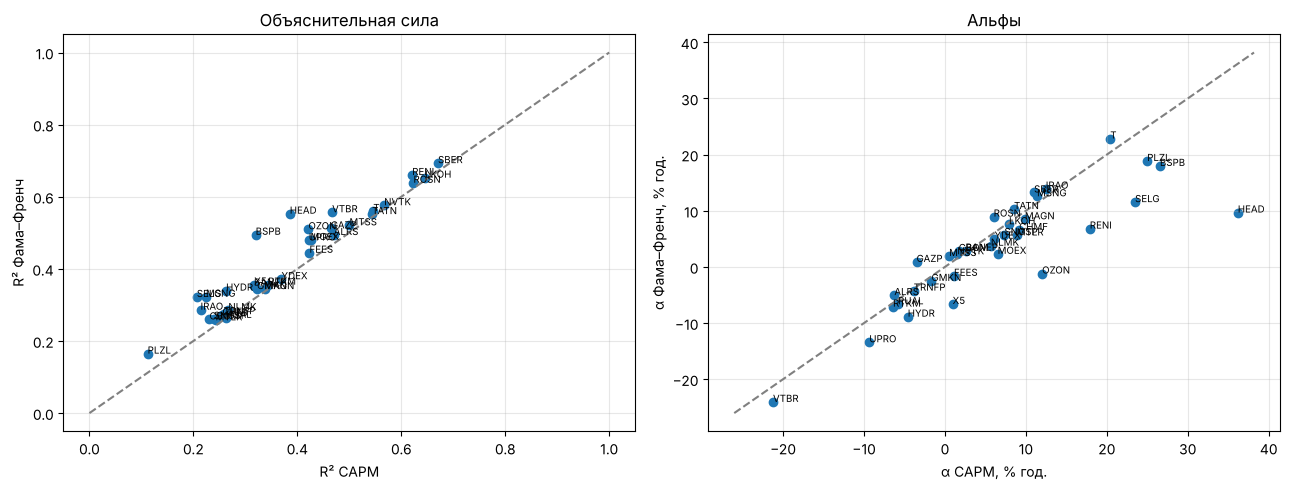

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(capm["R2"], ff3["R2"])
for t in ff3.index:
    ax.annotate(t, (capm.loc[t, "R2"], ff3.loc[t, "R2"]), fontsize=7)
ax.plot([0, 1], [0, 1], color="grey", ls="--")
ax.set_xlabel("R² CAPM"); ax.set_ylabel("R² Фама–Френч"); ax.set_title("Объяснительная сила")
ax = axes[1]
ax.scatter(capm["alpha_%год"], ff3["alpha_%год"])
for t in ff3.index:
    ax.annotate(t, (capm.loc[t, "alpha_%год"], ff3.loc[t, "alpha_%год"]), fontsize=7)
lim = [min(capm["alpha_%год"].min(), ff3["alpha_%год"].min()) - 2,
       max(capm["alpha_%год"].max(), ff3["alpha_%год"].max()) + 2]
ax.plot(lim, lim, color="grey", ls="--")
ax.set_xlabel("α CAPM, % год."); ax.set_ylabel("α Фама–Френч, % год."); ax.set_title("Альфы")
plt.tight_layout(); plt.savefig(FIG / "05_capm_vs_ff3.png", dpi=150); plt.show()

### 6.1. Процедура Фамы–Макбета: сколько рынок платит за единицу риска

Этап 1 — беты из временных регрессий выше. Этап 2 — каждый месяц поперечная регрессия
избыточных доходностей акций на их беты; $\lambda_k$ — среднее по месяцам, t-статистика по ряду $\lambda_{k,t}$.
Если модель верна, константа $\lambda_0 \approx 0$, а $\lambda_k$ близки к средним доходностям факторов.
35 отдельных акций — маленькая и шумная выборка (беты оценены с ошибкой), поэтому результат иллюстративный.

In [18]:
def fama_macbeth(EXR: pd.DataFrame, betas: pd.DataFrame) -> pd.DataFrame:
    lams = []
    for t, row in EXR.iterrows():
        d = pd.concat([row.rename("y"), betas], axis=1).dropna()
        if len(d) < 10:
            continue
        lams.append(sm.OLS(d["y"], sm.add_constant(d[betas.columns])).fit().params.rename(t))
    lam = pd.DataFrame(lams)
    return pd.DataFrame({"λ, % мес.": lam.mean() * 100,
                         "λ, % год.": lam.mean() * 1200,
                         "t-стат.": lam.mean() / lam.std() * np.sqrt(len(lam))})

fm_capm = fama_macbeth(EXR, capm[["MKT"]].astype(float))
fm_ff3 = fama_macbeth(EXR, ff3[["MKT", "SMB", "HML"]].astype(float))
fm = pd.concat({"CAPM": fm_capm, "Фама–Френч": fm_ff3})
fm["Ср. доходность фактора, % год."] = [np.nan, F["MKT"].mean() * 1200,
                                        np.nan, *(F.mean() * 1200)]
fm

λ, % мес.  λ, % год.  t-стат.  Ср. доходность фактора, % год.
CAPM       const     -0.019     -0.233   -0.028                             NaN
           MKT        0.888     10.652    0.961                           5.118
Фама–Френч const     -0.225     -2.697   -0.340                             NaN
           MKT        0.967     11.598    1.101                           5.118
           SMB        1.722     20.667    1.544                          17.907
           HML       -0.638     -7.656   -0.973                          -3.365

Константы близки к нулю, знаки премий совпадают со средними доходностями факторов (рынок и размер — плюс,
стоимость — минус), но все $\lambda$ статистически незначимы: на 35 акциях и 10 годах высоковолатильного рынка
цену риска точно оценить нельзя. Поэтому для расчёта премий ниже используем средние доходности факторов
(стандартный подход для торгуемых факторов), а оценки Фамы–Макбета — как проверку знаков.

## 7. Премии за риск и требуемая доходность: CAPM против Фамы–Френча

Премия за риск акции = сумма (бета × премия фактора). Премии факторов — их средние доходности за 02.2015–12.2024.
Требуемая (ожидаемая) доходность считается **на дату анализа**: безрисковая ставка — доходность 1-летних ОФЗ
с G-кривой ЦБ на конец последнего месяца данных (инвестор принимает решение сегодня, а не по средней ставке за 10 лет).

In [19]:
lam = F.mean() * 12                                        # годовые премии факторов
RF_NOW = mkt["ofz1y_annual"].dropna().iloc[-1]
RF_DATE = mkt["ofz1y_annual"].dropna().index[-1]
print(f"Безрисковая ставка на {RF_DATE}: {RF_NOW:.2%} (1-летние ОФЗ)")
print("Премии факторов, % год.:", (lam * 100).round(2).to_dict())

prem = pd.DataFrame({
    "Отрасль": pd.Series(SECTORS),
    "Премия CAPM": capm["MKT"] * lam["MKT"],
    "Премия ФФ: рынок": ff3["MKT"] * lam["MKT"],
    "Премия ФФ: размер": ff3["SMB"] * lam["SMB"],
    "Премия ФФ: стоимость": ff3["HML"] * lam["HML"],
}).dropna(subset=["Премия CAPM"])
prem["Премия ФФ"] = prem[["Премия ФФ: рынок", "Премия ФФ: размер", "Премия ФФ: стоимость"]].sum(axis=1)
prem["Разница ФФ − CAPM"] = prem["Премия ФФ"] - prem["Премия CAPM"]
prem["Факт. избыт. доходность"] = EXR.mean() * 12
prem["Треб. доходность CAPM"] = RF_NOW + prem["Премия CAPM"]
prem["Треб. доходность ФФ"] = RF_NOW + prem["Премия ФФ"]
num = prem.columns.drop("Отрасль")
prem[num] = prem[num].astype(float) * 100            # в % годовых
prem.sort_values("Разница ФФ − CAPM", ascending=False)

Безрисковая ставка на 2026-09: 13.72% (1-летние ОФЗ)
Премии факторов, % год.: {'MKT': 5.12, 'SMB': 17.91, 'HML': -3.37}


,Отрасль,Премия CAPM,Премия ФФ: рынок,Премия ФФ: размер,Премия ФФ: стоимость,Премия ФФ,Разница ФФ − CAPM,Факт. избыт. доходность,Треб. доходность CAPM,Треб. доходность ФФ
HEAD,Телеком и IT,8.503,9.865,9.048,5.910,24.822,16.320,38.215,22.223,38.542
SELG,Металлы и добыча,5.135,5.755,10.070,1.256,17.081,11.946,28.619,18.855,30.801
BSPB,Финансы,5.078,4.963,10.151,-1.460,13.655,8.577,31.639,18.798,27.375
OZON,Потребительский сектор,7.806,8.536,2.113,4.449,15.099,7.293,10.594,21.526,28.819
PLZL,Металлы и добыча,3.337,3.886,3.958,1.617,9.461,6.123,28.323,17.057,23.181
X5,Потребительский сектор,5.164,5.531,3.553,1.025,10.108,4.945,9.420,18.884,23.828
RENI,Финансы,6.558,6.693,3.158,1.612,11.463,4.906,4.160,20.278,25.183
HYDR,Электроэнергетика,3.365,3.323,4.969,-0.665,7.627,4.262,-1.233,17.085,21.347
MOEX,Финансы,4.474,4.496,4.549,-0.386,8.659,4.185,10.987,18.194,22.379
UPRO,Электроэнергетика,4.272,4.237,4.459,-0.463,8.233,3.961,-5.182,17.992,21.953


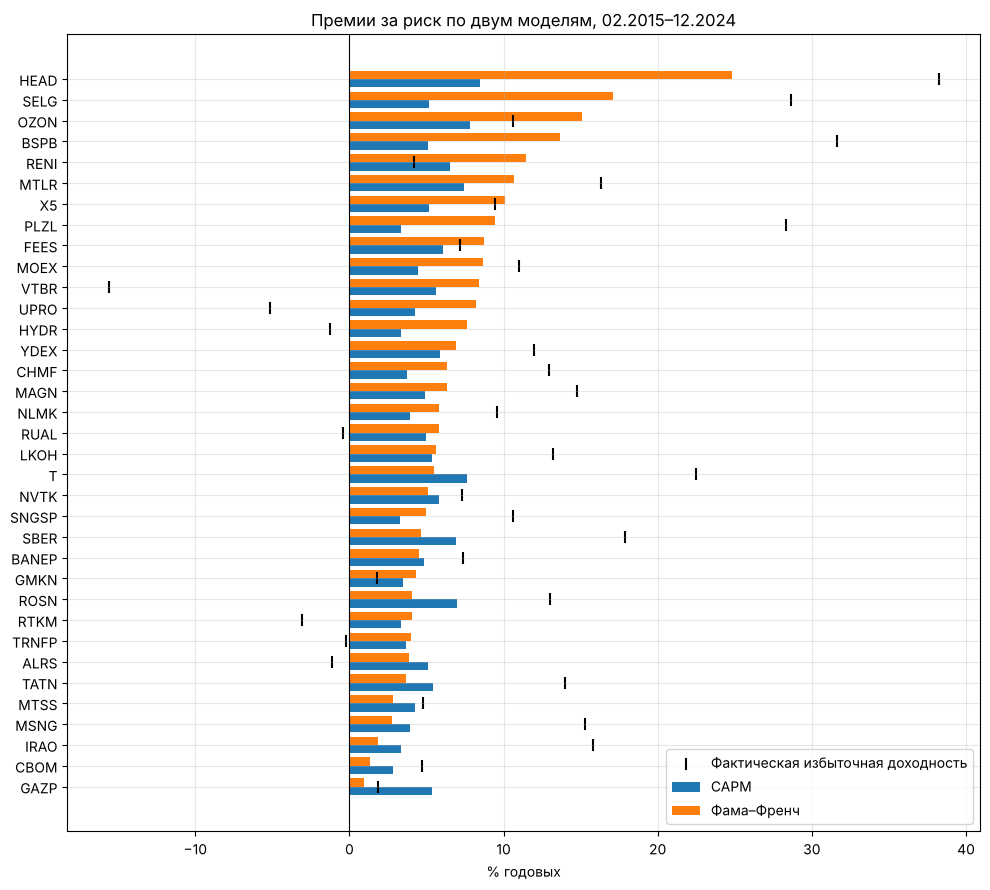

In [20]:
p = prem.sort_values("Премия ФФ")
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(p))
ax.barh(y - 0.2, p["Премия CAPM"], height=0.4, label="CAPM")
ax.barh(y + 0.2, p["Премия ФФ"], height=0.4, label="Фама–Френч")
ax.scatter(p["Факт. избыт. доходность"], y, color="black", marker="|", s=80, label="Фактическая избыточная доходность")
ax.set_yticks(y); ax.set_yticklabels(p.index)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% годовых"); ax.set_title("Премии за риск по двум моделям, 02.2015–12.2024")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "06_premia.png", dpi=150); plt.show()

**Сравнение премий за риск.**
* Для **крупных компаний** трёхфакторная премия равна или ниже CAPM: от +0,3 п.п. у LKOH до −2–3 п.п. у SBER, ROSN, TATN
  и −4,4 п.п. у GAZP. Причина — отрицательная нагрузка на SMB (это крупные бумаги, а малые в 2015–2024 гг. обгоняли)
  и, у «стоимостных» GAZP и SBER, отрицательная историческая премия HML. CAPM для них слегка завышает премию.
* Для **малых компаний** трёхфакторная модель даёт заметно более высокую премию: HEAD +16 п.п., SELG +12 п.п.,
  BSPB +9 п.п., OZON +7 п.п. CAPM занижает для них требуемую доходность (стоимость капитала).
* У BSPB, SELG, HEAD, X5 и MOEX фактическая доходность ближе к оценке ФФ, чем к CAPM: модель «доначисляет»
  премию за размер, которую CAPM записывает в альфу. У части малых бумаг (UPRO, HYDR, RENI) фактическая доходность
  ниже обеих оценок — их отставание факторы не объясняют.
* **Оговорка:** премия SMB (~18% годовых) сильно зависит от одного 2023 г. Использовать её как прогноз на будущее
  рискованно — для оценки стоимости капитала разумно брать более консервативную премию за размер.

## 8. Проверка устойчивости

Повторяем обе модели при других допущениях и смотрим, меняются ли выводы:
1. **Без дивидендов:** ценовые доходности акций, IMOEX, факторы РАНХиГС без дивидендов.
2. **Безрисковая ставка — ОФЗ 3М** вместо RUONIA.
3. **Рыночный фактор РАНХиГС** (широкий рынок с ограничением веса 15%, безрисковая — RGBI).
4. **Полный период CAPM 02.2015–09.2026** (для CAPM факторы РАНХиГС не нужны).

In [21]:
def model_summary(EXR, X) -> dict:
    t = run_model(EXR, X)
    return {"Средняя бета рынка": t[X.columns[0]].mean(), "Средний R²": t["R2"].mean(),
            "Средняя |α|, % год.": t["alpha_%год"].abs().mean(),
            "Значимых α": int((t["t_alpha"].abs() > 1.96).sum())}

rf_ofz = mkt["rf_ofz3m"]
specs = {
    "Основная": (EXR, F),
    "Без дивидендов": (
        ret_price.sub(mkt["rf_ruonia"], axis=0).loc[START:END],
        pd.DataFrame({"MKT": mkt["imoex_ret"] - mkt["rf_ruonia"],
                      "SMB": ranepa["SMB"], "HML": ranepa["HML"]}).loc[START:END]),
    "rf = ОФЗ 3М": (
        ret_total.sub(rf_ofz, axis=0).loc[START:END],
        F.assign(MKT=(mkt["mcftr_ret"] - rf_ofz).loc[START:END])),
    "Рынок РАНХиГС": (EXR, F.assign(MKT=ranepa["RM_TR"].loc[START:END])),
}
rob = {}
for name, (y, X) in specs.items():
    rob[(name, "CAPM")] = model_summary(y, X[["MKT"]])
    rob[(name, "ФФ")] = model_summary(y, X[["MKT", "SMB", "HML"]])
EXR_full = ret_total.sub(mkt["rf_ruonia"], axis=0).loc[START:"2026-09"]
MKT_full = (mkt["mcftr_ret"] - mkt["rf_ruonia"]).loc[START:"2026-09"].to_frame("MKT")
rob[("CAPM до 09.2026", "CAPM")] = model_summary(EXR_full, MKT_full)
robust = pd.DataFrame(rob).T
robust

Средняя бета рынка  Средний R²  Средняя |α|, % год.  Значимых α
Основная        CAPM               0.992       0.380                9.812       3.000
                ФФ                 1.004       0.423                8.108       3.000
Без дивидендов  CAPM               1.004       0.363               11.342       5.000
                ФФ                 1.010       0.407                9.638       5.000
rf = ОФЗ 3М     CAPM               0.993       0.380                9.734       3.000
                ФФ                 1.005       0.423                8.069       2.000
Рынок РАНХиГС   CAPM               0.993       0.290               13.546       9.000
                ФФ                 0.978       0.337               12.316       4.000
CAPM до 09.2026 CAPM               1.006       0.381                8.360       6.000

**Выводы устойчивы:**
* Замена RUONIA на ОФЗ 3М почти ничего не меняет (беты и R² те же, альфы сдвигаются на ~0,1 п.п.) —
  выбор безрисковой ставки не влияет на выводы, важно лишь, чтобы она менялась во времени.
* Без дивидендов альфы по модулю выше (≈11 п.п. против 10) и значимых больше: игнорирование дивидендов
  искажает результат — подтверждает выбор полных доходностей.
* С рыночным фактором РАНХиГС R² заметно ниже (0,29 против 0,38) и больше значимых альф: их широкий рынок
  с ограничением веса 15% и «безрисковой» RGBI хуже описывает наши крупные бумаги, чем MCFTR − RUONIA.
* На полном периоде до 09.2026 CAPM даёт те же беты и R².

## 9. Какие ещё факторы можно добавить

РАНХиГС публикует ещё факторы моментума (MOM, Carhart, 1997) и ликвидности (LIQ, близкий по смыслу к Pástor, Stambaugh, 2003).
Проверим, улучшают ли они объяснение доходностей поверх трёх факторов.

In [22]:
F5 = F.assign(MOM=ranepa["MOM_TR"], LIQ=ranepa["LIQ_TR"]).loc[START:END]
ext = {
    "CAPM": run_model(EXR, F5[["MKT"]]),
    "Фама–Френч (3)": ff3,
    "Кархарт (4: + MOM)": run_model(EXR, F5[["MKT", "SMB", "HML", "MOM"]]),
    "5 факторов (+ MOM, LIQ)": run_model(EXR, F5[["MKT", "SMB", "HML", "MOM", "LIQ"]]),
}
ext_tab = pd.DataFrame({k: {"Средний R²": v["R2"].mean(), "Средний скорр. R²": v["R2_adj"].mean(),
                            "Средняя |α|, % год.": v["alpha_%год"].abs().mean(),
                            "Значимых α": int((v["t_alpha"].abs() > 1.96).sum())}
                        for k, v in ext.items()}).T
for f in ["MOM", "LIQ"]:
    t = ext["5 факторов (+ MOM, LIQ)"][f"t_{f}"]
    ext_tab.loc["5 факторов (+ MOM, LIQ)", f"Значимых нагрузок {f}"] = int((t.abs() > 1.96).sum())
ext_tab

,Средний R²,Средний скорр. R²,"Средняя |α|, % год.",Значимых α,Значимых нагрузок MOM,Значимых нагрузок LIQ
CAPM,0.380,0.374,9.812,3.000,NaN,NaN
Фама–Френч (3),0.423,0.406,8.108,3.000,NaN,NaN
Кархарт (4: + MOM),0.433,0.410,8.336,3.000,NaN,NaN
"5 факторов (+ MOM, LIQ)",0.441,0.413,8.091,3.000,4.000,2.000


Моментум и ликвидность добавляют немного: скорректированный R² 0,406 → 0,413, средняя |α| почти не меняется,
значимые нагрузки на MOM — у 4 акций, на LIQ — у 2. Основная часть систематического риска уже покрыта рынком,
размером и стоимостью.

### Какие ещё факторы и модели можно рассмотреть (обзор литературы)

| Модель / фактор | Идея | Чем может помочь на российском рынке |
|---|---|---|
| Carhart (1997), моментум MOM | «Победители» последних 12 мес. продолжают расти | Объясняет инерцию трендов, которую не ловит ФФ3 |
| Fama, French (2015), RMW и CMA | Прибыльность и инвестиции компаний | Разделяет «дешёвые» качественные компании и компании в дистрессе |
| Hou, Xue, Zhang (2015), q-модель | Инвестиции и рентабельность из теории производства | Альтернатива ФФ5 с экономическим обоснованием |
| Pástor, Stambaugh (2003), Amihud (2002), ликвидность | Премия за неликвидность | Важна для второго эшелона (RENI, MSNG, UPRO) |
| Chen, Roll, Ross (1986), макрофакторы | Промпроизводство, инфляция, спреды | Для России — **цена нефти и курс рубля** (вся нефтегазовая выборка) |
| Фактор госсобственности SOE (РАНХиГС) | Акции госкомпаний несут политический риск | У VTBR, GAZP, HYDR, ALRS — объяснение части отрицательных альф |
| Условные CAPM (Jagannathan, Wang, 1996), DCC-беты | Беты меняются во времени | Беты до и после 2022 г. заметно различаются |

## 10. Рекомендации

1. **Для крупных ликвидных бумаг** (SBER, LKOH, ROSN, TATN, NVTK, GAZP, MTSS) CAPM даёт близкую или немного завышенную
   (на 0–4 п.п.) оценку требуемой доходности — для них простой модели достаточно. Для **малых компаний и бумаг
   роста/стоимости** (BSPB, SELG, HEAD, OZON, X5, HYDR, UPRO) следует использовать трёхфакторную модель — CAPM занижает
   их стоимость капитала на 4–16 п.п.
2. **«Альфа» по CAPM часто ложная.** Высокая доходность BSPB и HEAD в большой мере — плата за размер и стоимость;
   оценивать управляющих и инвестидеи нужно по альфе многофакторной модели.
3. **Значимая положительная альфа в модели ФФ — только у SBER** (+13% годовых, t = 1,99, на границе значимости):
   Сбербанк зарабатывал больше, чем требует его риск, — кандидат на перевес в портфеле, но с осторожностью.
   Значимо отрицательная альфа у VTBR и UPRO: исторически акционеры недополучали доход относительно принятого риска
   (допэмиссии, корпоративные события) — при прочих равных такие бумаги стоит недовешивать.
4. **Для защитного портфеля** — акции с низкой рыночной бетой (CBOM, SNGSP, TRNFP, IRAO, RTKM, PLZL);
   для ставки на рост рынка — высокобетовые (HEAD, OZON, T, ROSN, SBER).
5. Требуемую доходность считать от **текущей** безрисковой ставки (1-летние ОФЗ 13,7% на 09.2026), а премию за размер
   брать консервативнее исторической — её оценка неустойчива.

## 11. Заключение

* На 35 российских акциях в 2015–2024 гг. рыночный фактор объясняет ~38% колебаний доходности; добавление факторов
  размера и стоимости повышает R² до ~42% и снижает средние ошибки ценообразования на 1,7 п.п. в год.
* Нагрузки на SMB и HML экономически осмысленны и значимы у трети выборки; премия за размер в России была высокой (2023 г.),
  премия за стоимость — отрицательной.
* Обе модели формально отвергаются GRS-тестом, но трёхфакторная — заметно ближе к цели. Выводы устойчивы к выбору
  безрисковой ставки, учёту дивидендов и периоду; моментум и ликвидность дают лишь небольшое улучшение.

## 12. Выгрузка результатов в Excel (для презентации)

In [23]:
with pd.ExcelWriter(RES / "hw2_results.xlsx") as xw:
    desc.to_excel(xw, sheet_name="Описательная статистика")
    fac_stats.to_excel(xw, sheet_name="Факторы")
    capm_view.to_excel(xw, sheet_name="CAPM")
    ff3_view.to_excel(xw, sheet_name="Фама-Френч")
    compare.to_excel(xw, sheet_name="Сравнение моделей")
    fm.to_excel(xw, sheet_name="Фама-Макбет")
    prem.to_excel(xw, sheet_name="Премии за риск")
    robust.to_excel(xw, sheet_name="Устойчивость")
    ext_tab.to_excel(xw, sheet_name="Доп. факторы")
    summary_rf.to_excel(xw, sheet_name="Безрисковая ставка")
print("Сохранено:", RES / "hw2_results.xlsx")

Сохранено: results/hw2_results.xlsx
